In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('/kaggle/input/heart-failure-prediction/heart.csv')

## **Exploratory Data Analysis EDA**

In [4]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


### **Univariate Analysis**

**Age**

In [14]:
df['Age']

0      40
1      49
2      37
3      48
4      54
       ..
913    45
914    68
915    57
916    57
917    38
Name: Age, Length: 918, dtype: int64

In [15]:
df['Age'].describe()

count    918.000000
mean      53.510893
std        9.432617
min       28.000000
25%       47.000000
50%       54.000000
75%       60.000000
max       77.000000
Name: Age, dtype: float64

<Axes: ylabel='Density'>

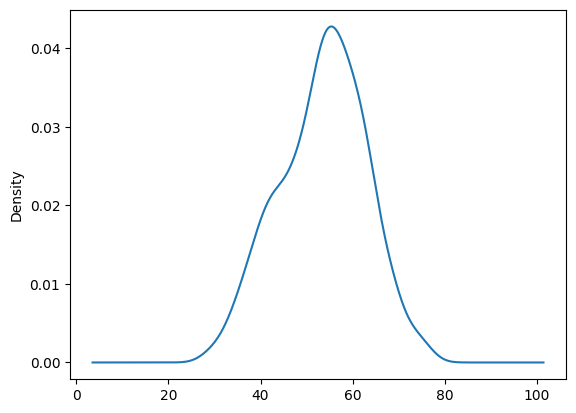

In [18]:
df['Age'].plot(kind='kde')

**Sex**

In [19]:
df['Sex']

0      M
1      F
2      M
3      F
4      M
      ..
913    M
914    M
915    M
916    F
917    M
Name: Sex, Length: 918, dtype: object

In [32]:
np.round(df['Sex'].value_counts(normalize=True) * 100, 2)

Sex
M    78.98
F    21.02
Name: proportion, dtype: float64

<Axes: xlabel='Sex'>

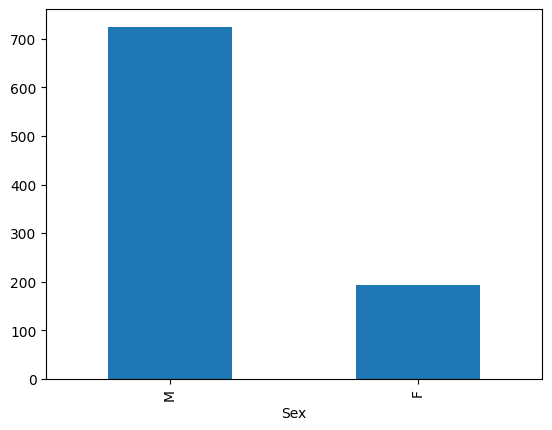

In [23]:
df['Sex'].value_counts().plot(kind='bar')

<Axes: ylabel='count'>

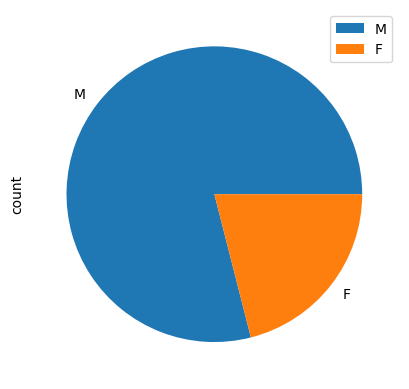

In [33]:
df['Sex'].value_counts().plot(kind='pie', legend=True)

- Males more than Females
- 

In [34]:
df['ChestPainType'].value_counts()

ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64

<Axes: xlabel='ChestPainType'>

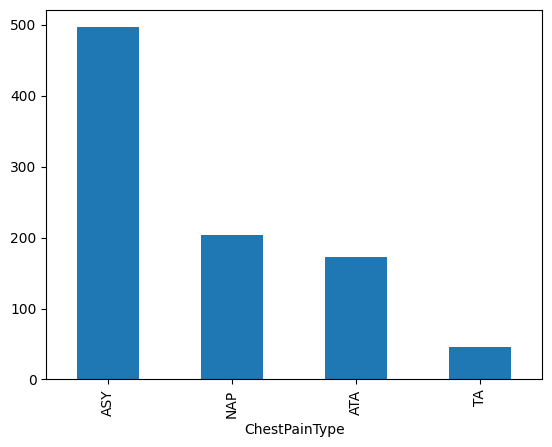

In [38]:
df['ChestPainType'].value_counts().plot(kind='bar')

- ASY is 
- 
- 

In [60]:
df[df['ChestPainType'] == 'NAP']

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
10,37,F,NAP,130,211,0,Normal,142,N,0.0,Up,0
14,42,F,NAP,115,211,0,ST,137,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
891,66,F,NAP,146,278,0,LVH,152,N,0.0,Flat,0
892,39,F,NAP,138,220,0,Normal,152,N,0.0,Flat,0
896,47,M,NAP,130,253,0,Normal,179,N,0.0,Up,0
905,67,M,NAP,152,212,0,LVH,150,N,0.8,Flat,1


### **Bivariate Analysis**

In [55]:
df.groupby(['ChestPainType'])['Sex'].value_counts().idxmax()

('ASY', 'M')

In [59]:
df[(df['ChestPainType'] == 'ASY') & (df['Age'] > 50)]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
18,60,M,ASY,100,248,0,Normal,125,N,1.0,Flat,1
26,53,M,ASY,124,260,0,ST,112,Y,3.0,Flat,0
32,54,M,ASY,125,224,0,Normal,122,N,2.0,Flat,1
36,65,M,ASY,140,306,1,Normal,87,Y,1.5,Flat,1
58,54,M,ASY,150,365,0,ST,134,N,1.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
900,58,M,ASY,114,318,0,ST,140,N,4.4,Down,1
908,63,M,ASY,140,187,0,LVH,144,Y,4.0,Up,1
911,59,M,ASY,164,176,1,LVH,90,N,1.0,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1


In [57]:
df.groupby(['ChestPainType'])['Age'].max()

ChestPainType
ASY    77
ATA    74
NAP    76
TA     74
Name: Age, dtype: int64

In [61]:
df.groupby('Cholesterol')['RestingBP'].mean()

Cholesterol
0      129.680233
85     120.000000
100    130.000000
110    140.000000
113    104.000000
          ...    
491    135.000000
518    145.000000
529    118.000000
564    115.000000
603    130.000000
Name: RestingBP, Length: 222, dtype: float64

### **Multivariate Analysis**

In [64]:
df[(df['ChestPainType'] == 'NAP') & (df['Age'] > 60) & (df['Sex'] == 'F')]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
375,73,F,NAP,160,0,0,ST,121,N,0.0,Up,1
616,67,F,NAP,115,564,0,LVH,160,N,1.6,Flat,0
644,71,F,NAP,110,265,1,LVH,130,N,0.0,Up,0
667,65,F,NAP,140,417,1,LVH,157,N,0.8,Up,0
688,76,F,NAP,140,197,0,ST,116,N,1.1,Flat,0
713,64,F,NAP,140,313,0,Normal,133,N,0.2,Up,0
738,65,F,NAP,160,360,0,LVH,151,N,0.8,Up,0
751,67,F,NAP,152,277,0,Normal,172,N,0.0,Up,0
788,68,F,NAP,120,211,0,LVH,115,N,1.5,Flat,0
831,63,F,NAP,135,252,0,LVH,172,N,0.0,Up,0


In [66]:
df.groupby(['ChestPainType', 'Sex'])['Age'].mean()

ChestPainType  Sex
ASY            F      54.257143
               M      55.075117
ATA            F      49.583333
               M      49.061947
NAP            F      53.132075
               M      53.373333
TA             F      54.200000
               M      55.000000
Name: Age, dtype: float64

In [72]:
df.corr(numeric_only=True)    # -1 0 1

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
Age,1.000000,0.254399,-0.095282,0.198039,-0.382045,0.258612,0.282039
RestingBP,0.254399,1.000000,0.100893,0.070193,-0.112135,0.164803,0.107589
Cholesterol,-0.095282,0.100893,1.000000,-0.260974,0.235792,0.050148,-0.232741
FastingBS,0.198039,0.070193,-0.260974,1.000000,-0.131438,0.052698,0.267291
MaxHR,-0.382045,-0.112135,0.235792,-0.131438,1.000000,-0.160691,-0.400421
Oldpeak,0.258612,0.164803,0.050148,0.052698,-0.160691,1.000000,0.403951
HeartDisease,0.282039,0.107589,-0.232741,0.267291,-0.400421,0.403951,1.000000


## **Preprocessing**

In [73]:
df.isna().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [75]:
df.dropna(inplace=True)

In [88]:
df.rename(columns={'Sex':'Gender'}, inplace=True)

In [89]:
df

,Age,Gender,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [91]:
df[df.duplicated()]

,Age,Gender,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease


In [92]:
df.drop_duplicates(inplace=True)